# Notebook 3 — Audio Feature Extraction

Extract librosa audio descriptors from traffic-derived signals:
**MFCC, Mel Spectrogram, Chroma, Spectral Contrast, Tonnetz, ZCR, Spectral Centroid, RMS**


In [1]:
import sys
sys.path.insert(0, '../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display

from preprocessing import DataLoader, FeatureProcessor
from signal_generator import SignalGenerator
from audio_features import AudioFeatureExtractor

FIG_DIR = '../reports/figures'
import os; os.makedirs(FIG_DIR, exist_ok=True)
SAMPLE_SIZE = 300


In [2]:
loader = DataLoader(data_dir='../data/raw')
train_df, _ = loader.load_nsl_kdd(sample_size=SAMPLE_SIZE)
processor = FeatureProcessor()
X, y, _ = processor.prepare_features(train_df, fit=True)

sig_gen = SignalGenerator()
sig_gen.fit(X)
signals = sig_gen.generate_batch(X)

extractor = AudioFeatureExtractor()
print(f"Signal shape: {signals.shape}")
print(f"Feature names count: {len(extractor.get_feature_names(signals[0]))}")


Signal shape: (300, 44100)


Feature names count: 352


C:\Users\kaavi\OneDrive\Desktop\Audio-Based-Network-Intrusion-Detection-System\venv\Lib\site-packages\librosa\core\spectrum.py:266: UserWarning: n_fft=1024 is too large for input signal of length=690
  warnings.warn(


## MFCC Heatmaps


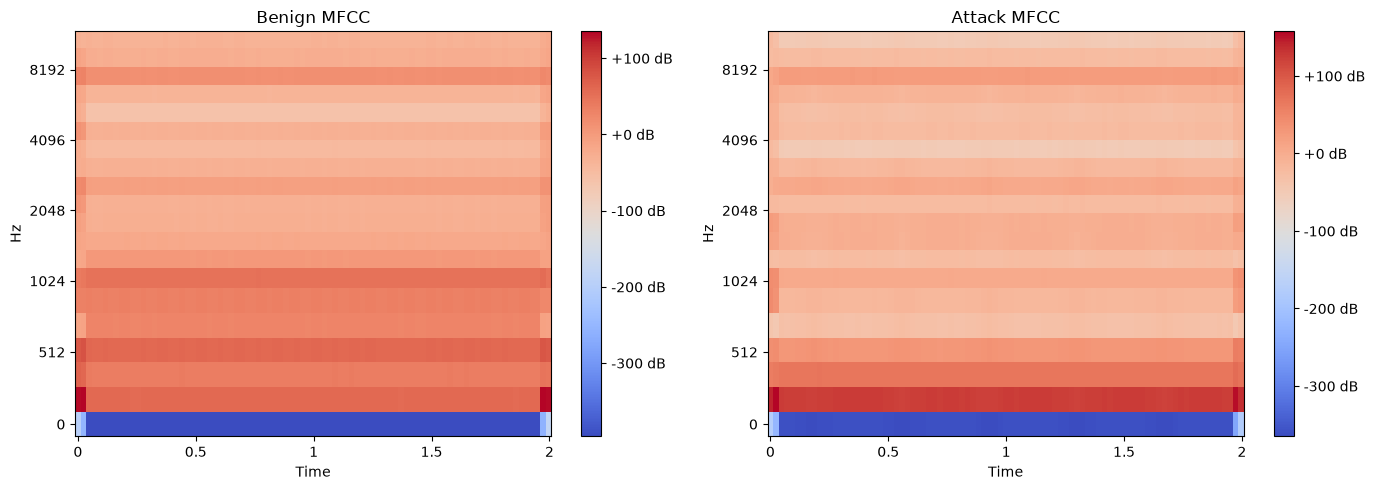

In [3]:
benign_s = signals[y == 0][0]
attack_s = signals[y == 1][0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, sig, title in [(axes[0], benign_s, 'Benign MFCC'), (axes[1], attack_s, 'Attack MFCC')]:
    mfcc = librosa.feature.mfcc(y=sig, sr=22050, n_mfcc=20)
    img = librosa.display.specshow(mfcc, x_axis='time', y_axis='mel', ax=ax, sr=22050)
    ax.set_title(title)
    fig.colorbar(img, ax=ax, format='%+2.0f dB')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/12_mfcc_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()


## Mel Spectrograms


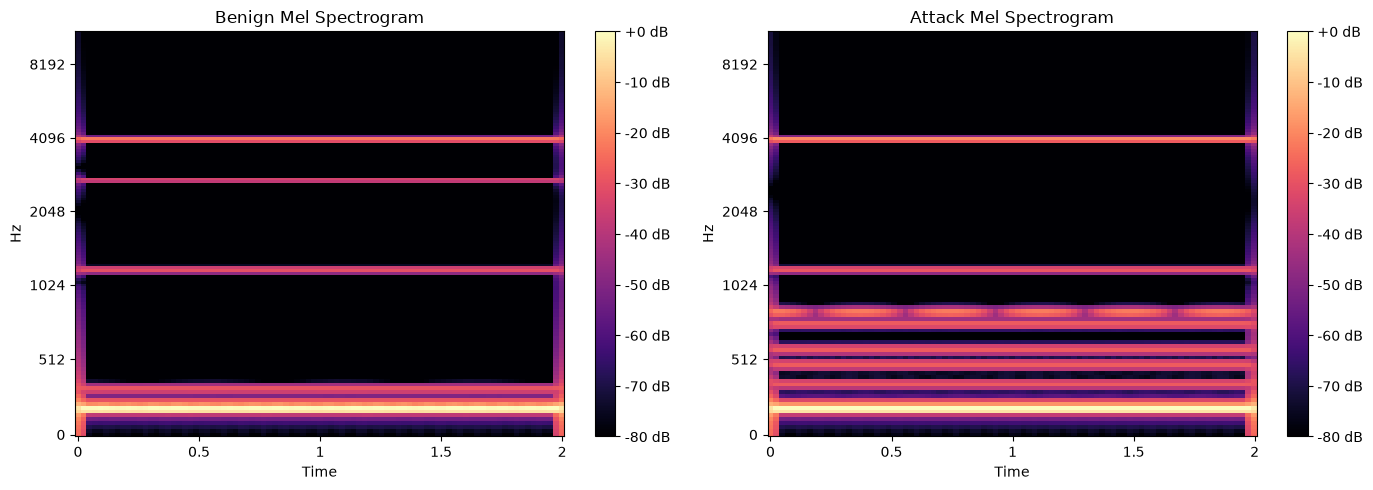

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, sig, title, cmap in [
    (axes[0], benign_s, 'Benign Mel Spectrogram', 'magma'),
    (axes[1], attack_s, 'Attack Mel Spectrogram', 'magma'),
]:
    mel = librosa.feature.melspectrogram(y=sig, sr=22050, n_mels=128)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    img = librosa.display.specshow(mel_db, x_axis='time', y_axis='mel', ax=ax, sr=22050, cmap=cmap)
    ax.set_title(title)
    fig.colorbar(img, ax=ax, format='%+2.0f dB')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/13_mel_spectrogram.png', dpi=300, bbox_inches='tight')
plt.show()


## Chroma & Spectral Features


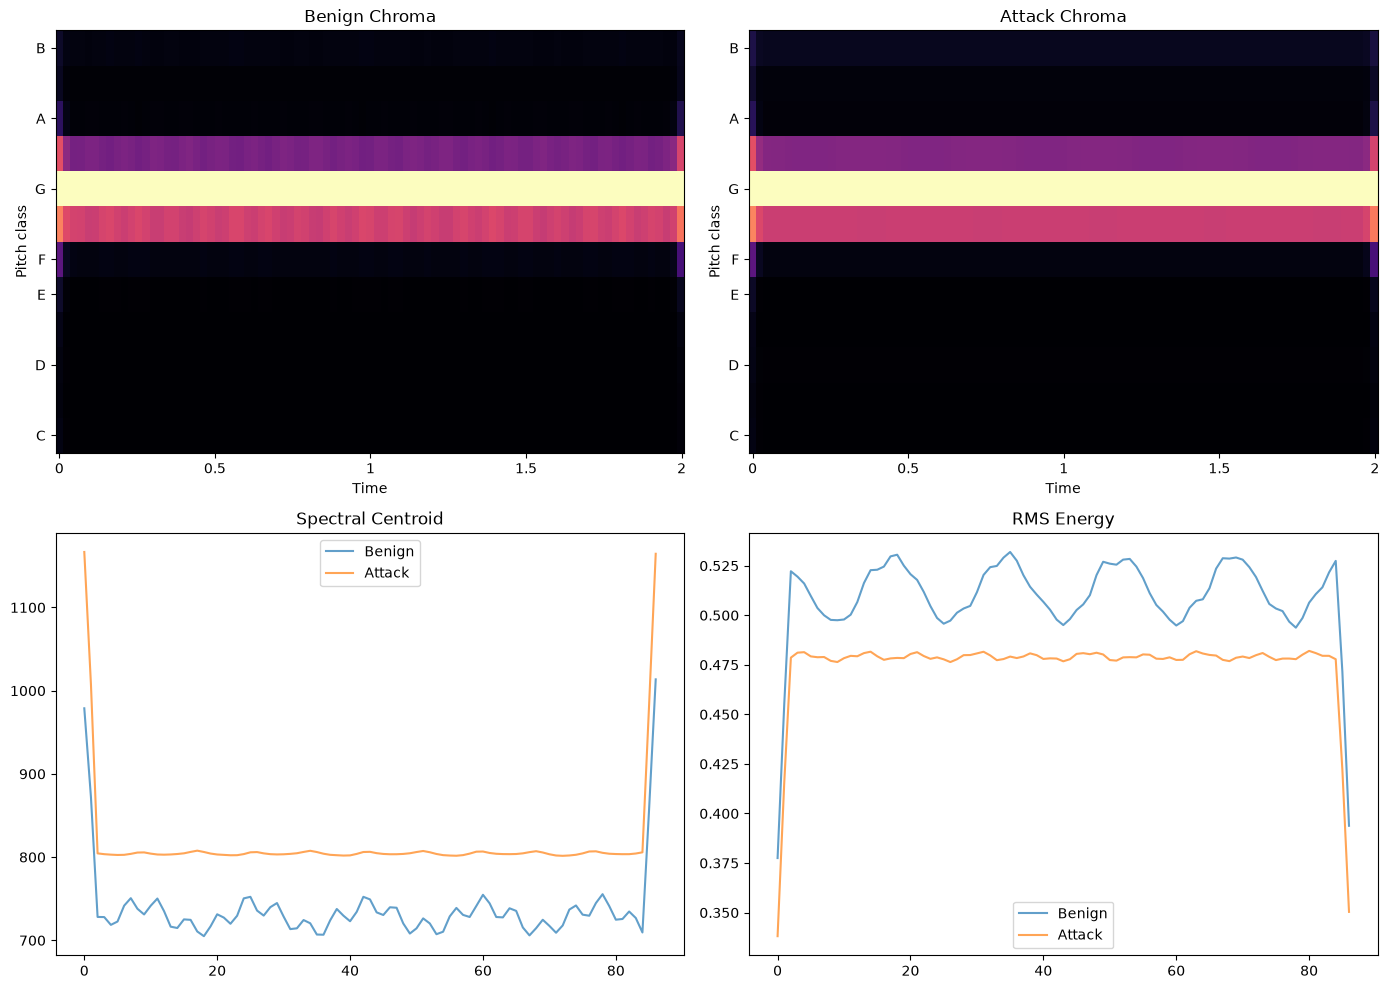

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
features_b = extractor.extract_all(benign_s)
features_a = extractor.extract_all(attack_s)

librosa.display.specshow(features_b['chroma'], x_axis='time', y_axis='chroma', ax=axes[0,0])
axes[0,0].set_title('Benign Chroma')
librosa.display.specshow(features_a['chroma'], x_axis='time', y_axis='chroma', ax=axes[0,1])
axes[0,1].set_title('Attack Chroma')

axes[1,0].plot(features_b['spectral_centroid'].T, alpha=0.7, label='Benign')
axes[1,0].plot(features_a['spectral_centroid'].T, alpha=0.7, label='Attack')
axes[1,0].set_title('Spectral Centroid'); axes[1,0].legend()

axes[1,1].plot(features_b['rms'].T, alpha=0.7, label='Benign')
axes[1,1].plot(features_a['rms'].T, alpha=0.7, label='Attack')
axes[1,1].set_title('RMS Energy'); axes[1,1].legend()

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/14_chroma_spectral.png', dpi=300, bbox_inches='tight')
plt.show()


## Feature Vectors for Training


In [6]:
audio_features_df = extractor.features_to_dataframe(signals, labels=y)
audio_features_df['is_attack'] = y
audio_features_df.to_csv('../data/processed/audio_features.csv', index=False)
print(f"Audio feature matrix: {audio_features_df.shape}")
audio_features_df.head()


Audio feature matrix: (300, 354)


,mfcc_0_mean,mfcc_0_std,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,mfcc_4_mean,mfcc_4_std,...,tonnetz_5_mean,tonnetz_5_std,zcr_0_mean,zcr_0_std,spectral_centroid_0_mean,spectral_centroid_0_std,rms_0_mean,rms_0_std,label,is_attack
0,-387.737701,37.203781,62.583214,15.500580,37.549942,4.199111,60.920372,3.752795,25.812210,8.206358,...,-0.225471,0.034966,0.032934,0.003483,737.938965,46.363964,0.508551,0.023211,0,0
1,-354.249573,33.308510,125.155602,5.329780,68.693802,1.630212,31.898245,4.764686,-31.354357,3.257854,...,-0.206258,0.030702,0.043710,0.005876,816.931702,60.686680,0.474614,0.022016,1,1
2,-391.131439,37.758953,73.297920,11.447061,58.310230,4.489913,76.377708,4.476647,8.892659,9.428894,...,-0.207388,0.031430,0.043059,0.003907,847.863464,58.159904,0.492211,0.022559,1,1
3,-368.982086,34.279663,107.974785,7.849073,70.589783,0.965565,54.329609,2.506853,-0.321027,7.216406,...,-0.182835,0.027332,0.043154,0.004314,796.160767,58.429634,0.489464,0.022390,1,1
4,-391.504059,38.115284,53.256195,13.618026,29.365654,5.372992,84.766869,5.193144,46.999722,8.995474,...,-0.225148,0.034781,0.033983,0.004463,891.302246,44.427383,0.503013,0.023325,1,1


In [7]:
# Compare benign vs attack profiles
profile = extractor.compare_attack_profiles(signals[y==0][:50], signals[y==1][:50])
profile.head(15)


C:\Users\kaavi\OneDrive\Desktop\Audio-Based-Network-Intrusion-Detection-System\venv\Lib\site-packages\librosa\core\spectrum.py:266: UserWarning: n_fft=1024 is too large for input signal of length=690
  warnings.warn(


,feature,benign_mean,attack_mean,difference,abs_difference
348,spectral_centroid_0_mean,680.188293,792.912476,112.724182,112.724182
80,mel_spectrogram_20_mean,-73.455467,-51.982975,21.472492,21.472492
78,mel_spectrogram_19_mean,-70.588669,-50.043747,20.544922,20.544922
82,mel_spectrogram_21_mean,-72.022346,-52.398682,19.623665,19.623665
22,mfcc_11_mean,-15.308811,1.977593,17.286404,17.286404
14,mfcc_7_mean,-12.912235,-29.354164,-16.441929,16.441929
2,mfcc_1_mean,70.825256,87.182800,16.357544,16.357544
88,mel_spectrogram_24_mean,-74.767456,-58.488750,16.278706,16.278706
84,mel_spectrogram_22_mean,-71.801048,-56.766914,15.034134,15.034134
8,mfcc_4_mean,22.838055,8.250481,-14.587574,14.587574


**Next:** [Notebook 4 — Baseline Models](04_baseline_models.ipynb)
